# Rb 21Ne
using diffrax backend. Uses spylind 0.2 from pypi

In [1]:
# Need to make sure jax is set to 64 bit before it's used anywhere in code
import jax
jax.config.update("jax_enable_x64", True)



In [2]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
from pylab import *
import jax.numpy as jnp
from numpy import pi
from spylind import spyIVP as so
import sympy as sm;
import pdb
sm.init_printing()
import co_mag_model as m
import fit_stats as fs
import matplotlib

plt.style.use('dark_background')
#plt.style.use('default')

font = {
        'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 14}
matplotlib.rc('font', **font)
pltColors = rcParams['axes.prop_cycle'].by_key()['color'] 

In [3]:
d_dtD = m.get_d_dtDs()
alk_dt = d_dtD['alk']
nob_dt = d_dtD['nob']

s = m.s

In [4]:
state_syms = sm.Matrix( list(alk_dt[0]) + list(nob_dt[0]))
d_dt= sm.Matrix( list(alk_dt[1]) + list(nob_dt[1]))

In [5]:
state_syms, d_dt

⎛⎡P_x__e⎤  ⎡Ω_y⋅P_z__e - Ω_z⋅P_y__e - P_x__e⋅(R_{sd}__e + R_{se}__{en} + Rₚ) + ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎜⎢P_y__e⎥  ⎢ -Ωₓ⋅P_z__e + Ω_z⋅P_x__e - P_y__e⋅(R_{sd}__e + R_{se}__{en} + Rₚ)  ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎜⎢P_z__e⎥  ⎢ Ωₓ⋅P_y__e - Ω_y⋅P_x__e - P_z__e⋅(R_{sd}__e + R_{se}__{en} + Rₚ) + ↪
⎜⎢      ⎥, ⎢                                                                   ↪
⎜⎢ Pⁿₓ  ⎥  ⎢       Ω_y⋅P_z__n - Ω_z⋅P_y__n + P_x__e⋅R_{se}__{ne} - Pⁿₓ⋅R_{dec} ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎜⎢P_y__n⎥  ⎢        -Ωₓ⋅P_z__n + Ω_z⋅Pⁿₓ + P_y__e⋅R_{se}__{ne} - P_y__n⋅R_{dec ↪
⎜⎢      ⎥  ⎢                                                                   ↪
⎝⎣P_z__n⎦  ⎣                  Ωₓ⋅P_y__n - Ω_y⋅Pⁿₓ + P_z__e⋅R_{se}__{ne} - P_z_ ↪

↪  Pⁿₓ⋅R_{se}__{en} + Rₘ⋅s_x__m + Rₚ⋅s_x__p + γₑ⋅(-P_y__e⋅(B_z + Mₙ⋅P_z__n⋅λ + ↪
↪                          

In [6]:
subD =  dict( zip(s.Om_v[1:], [0,0]) )  \
        |dict( zip(s.sp_v, [0,0,1]) ) \
        |dict( zip(s.anom_e_v, [0,0,0]) ) \
        |dict( zip(s.sm_v, [0,0,0]) )\
        | {s.B_v[2] : s.Bbias}\
        |{s.anom_n_v[0]:0, s.anom_n_v[1]:0 } # don't set Beta[2]- it's for necom pulses 


        
constantsD = {
    s.y_n : .00336*2*np.pi,# 21Ne
    #s.y_n : .0324*2*np.pi,#.0324*2*pi, #Hz/nT 0.011 0.0324

    s.R_n_sd : 1e-10, #/s
    s.R_n_dec : .2,
    s.y_e : 7*2*np.pi, #Hz/nT
    s.R_e_sd : 100, #/s
    s.Rm :0,
    s.lam: 1,
    s.Me: 50,
    s.Mn: 100*5,
    s.R_ne_se: 0,
    s.R_en_se: 0,
} 

In [7]:

subD |= constantsD
evoD = {sym:d_dt for sym,d_dt in zip(state_syms, d_dt.subs(subD))}

#bias_ax = 200*np.linspace(0,1,5)**1.5
#bias_ax -= bias_ax[0] + (bias_ax[1]-bias_ax[0])/2
#bias_ax = np.hstack([-bias_ax[::-1], bias_ax])
#bias_ax = -np.array([100, 150,200, 250], dtype='f8')
bias_ax = -np.linspace(60, 150, 100)
#bias_ax = -np.linspace(370, 460, 30)
ode_s = so.ODESys(evoD, tSym = s.t, trans_dims={s.Bbias:bias_ax}, driving_syms=[ s.Rp, s.anom_n_v[2], s.Om_v[0], s.B_v[0],s.B_v[1] ])
ode_s.set_initial_state(np.array([0,0.,0,  0, 0, 0.2])) 
#ode_s.set_constants({T1:10, T2:20, Rx:0, Ry:0})

ode_s.summary()

**Function signatures:**

state_dep_f( $\displaystyle t$, dimAxes = $[ \displaystyle B_{bias} ]$, state = $[ \displaystyle P^{e}_{x}, \displaystyle P^{e}_{y}, \displaystyle P^{e}_{z}, \displaystyle P^{n}_{x}, \displaystyle P^{n}_{y}, \displaystyle P^{n}_{z} ]$, driving= $[ \displaystyle R_{p}, \displaystyle \beta_{n z}, \displaystyle \Omega_{x}, \displaystyle B_{x}, \displaystyle B_{y} ]$, intermediate = $[  ]$ )

output_f( $\displaystyle t$, dimAxes = $[ \displaystyle B_{bias} ]$, state = $[ \displaystyle P^{e}_{x}, \displaystyle P^{e}_{y}, \displaystyle P^{e}_{z}, \displaystyle P^{n}_{x}, \displaystyle P^{n}_{y}, \displaystyle P^{n}_{z} ]$, driving= $[ \displaystyle R_{p}, \displaystyle \beta_{n z}, \displaystyle \Omega_{x}, \displaystyle B_{x}, \displaystyle B_{y} ]$, state_dependent= $[  ]$ , intermediate = $[  ]$ )

**Variables:**

<IPython.core.display.Latex object>

...

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [12]:
tau = 0.01
solver_opts = {
        #'max_step': tau*0.05/2, #half the width of the large pulses. The new diffrax step updating algorithm seems to manage without, but
                        #uncomment if it starts skipping over pulses
        'nsteps': int(1e9) # diffrax has a habit of churning forever if things go wrong, so setting a maximum number of steps is handy
              }
pert_amp = 1e-4

ode_s.set_driving({
                   s.Rp:m.make_repeating_pulse_func_jax(period= tau,rel_width=0.05, pulse_area=10),
                   s.anom_n_v[2]:m.make_alternating_pulse_func_jax(period=tau, rel_width=0.05, pulse_area=1*jnp.pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: pert_amp,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]: 0e-4,


                  })
model = ode_s.setup_model(backend='diffrax', solver_opts=solver_opts)
tEnd = 10
tSteps = np.arange(2*tau, tEnd, 0.005)
endSteps = tEnd+np.arange(0,2*tau, 0.00001)
tSteps = np.hstack([ tSteps, endSteps ])
%time res_bx =model.integrate(tSteps)



endSlc = slice(-len(endSteps),None)
mainSlc = slice(0, -len(endSteps))


CPU times: user 3.83 s, sys: 116 ms, total: 3.94 s
Wall time: 2.76 s


Text(0.5, 1.0, 'noble evolution, bias: -75.5')

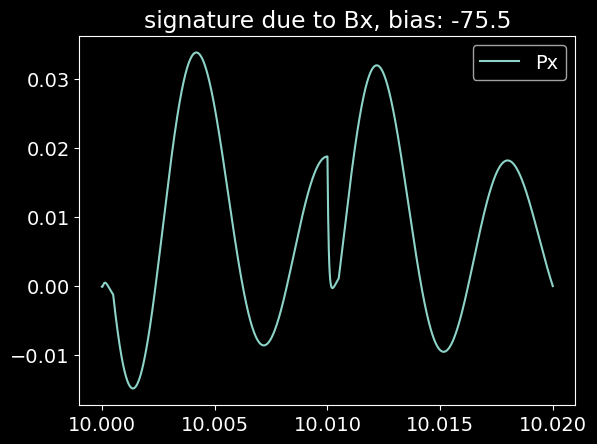

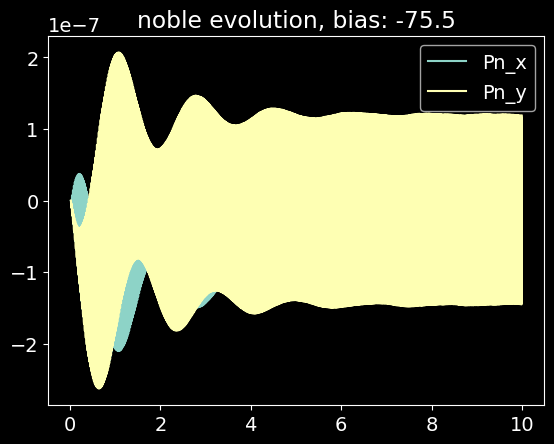

In [10]:
bias_ind = (-bias_ax).searchsorted(75)
bias_actual = bias_ax[bias_ind]
plt.plot(tSteps[endSlc], res_bx[endSlc, 0,bias_ind]/pert_amp, label = ['Px'])
plt.legend()
plt.title(f'signature due to Bx, bias: {bias_actual:.1f}')
plt.figure()
plt.plot(tSteps[mainSlc], res_bx[mainSlc,3:5, bias_ind], label= ['Pn_x', 'Pn_y'])
plt.legend()
plt.title(f'noble evolution, bias: {bias_actual:.1f}')


# Comparison with numpy

(make sure to use the non-diffrax pulse functions or it may churn and fail)

In [18]:
tau = 0.01
solver_opts = {
        #'max_step': tau*0.05/2, #half the width of the large pulses. The new diffrax step updating algorithm seems to manage without, but
                        #uncomment if it starts skipping over pulses
        'nsteps': int(1e9) # diffrax has a habit of churning forever if things go wrong, so setting a maximum number of steps is handy
              }
pert_amp = 1e-4

ode_s.set_driving({
                   s.Rp:m.make_repeating_pulse_func(period= tau,rel_width=0.05, pulse_area=10),
                   s.anom_n_v[2]:m.make_alternating_pulse_func(period=tau, rel_width=0.05, pulse_area=1*jnp.pi/2, gamma = constantsD[s.y_n]),
                   s.B_v[0]: pert_amp,
                    s.B_v[1]: 0e-4,
                   s.Om_v[0]: 0e-4,


                  })
model = ode_s.setup_model(backend='numpy', solver_opts=solver_opts)
tEnd = 10
tSteps = np.arange(2*tau, tEnd, 0.005)
endSteps = tEnd+np.arange(0,2*tau, 0.00001)
tSteps = np.hstack([ tSteps, endSteps ])
%time res_bx_np =model.integrate(tSteps)



endSlc = slice(-len(endSteps),None)
mainSlc = slice(0, -len(endSteps))


CPU times: user 32.7 s, sys: 2.96 ms, total: 32.7 s
Wall time: 32.9 s


Text(0.5, 1.0, 'signature due to Bx, bias: -75.5')

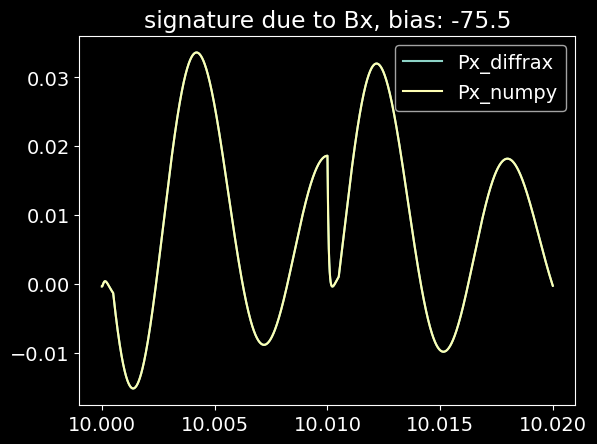

In [19]:
bias_ind = (-bias_ax).searchsorted(75)
bias_actual = bias_ax[bias_ind]
plt.plot(tSteps[endSlc], res_bx[endSlc, 0,bias_ind]/pert_amp, label = ['Px_diffrax'])
plt.plot(tSteps[endSlc], res_bx_np[endSlc, 0,bias_ind]/pert_amp, label = ['Px_numpy'])

plt.legend()
plt.title(f'signature due to Bx, bias: {bias_actual:.1f}')
